# Exploratory data analysis (Milestone 1)

A first look at the raw recordings and at the chunks created by `smart_chunk_wav.py`.

Data (not tracked in git):

```
data/unchunked/allowed/<speaker>/*.wav   raw recordings of allowed speakers
data/unchunked/not_allowed/*.wav         FLEURS recordings + metadata.csv
data/allowed/                            chunks, smart_chunk_wav.py --label 1
data/not_allowed/                        Common Voice chunks (audios_mult, audios_pl, audios_tr, eng)
```

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt

root = Path.cwd().parent if Path.cwd().name == "m1" else Path.cwd()
data = root / "data"
raw_dir = data / "unchunked"

## 1. Recordings

In [2]:
rows = []
for folder in ["allowed", "not_allowed"]:
    for path in sorted((raw_dir / folder).rglob("*.wav")):
        audio, sr = sf.read(path, always_2d=True)
        rows.append({
            "file": path.relative_to(raw_dir / folder).as_posix(),
            "class": folder.replace("_", " "),
            "speaker": path.parent.name if folder == "allowed" else "FLEURS",
            "sample_rate": sr,
            "channels": audio.shape[1],
            "duration": len(audio) / sr,
            "rms_db": 20 * np.log10(np.sqrt(np.mean(audio ** 2))),
        })

recordings = pd.DataFrame(rows)

recordings.groupby("class").agg(
    recordings=("file", "count"),
    total_min=("duration", lambda s: s.sum() / 60),
    mean_duration=("duration", "mean"),
    min_duration=("duration", "min"),
    max_duration=("duration", "max"),
).round(1)

,recordings,total_min,mean_duration,min_duration,max_duration
class,,,,,
allowed,19,61.6,194.5,71.7,348.8
not allowed,180,30.8,10.3,3.8,23.4


In [3]:
allowed_raw = recordings[recordings["class"] == "allowed"]

allowed_raw.groupby("speaker").agg(
    recordings=("file", "count"),
    total_min=("duration", lambda s: s.sum() / 60),
    sample_rates=("sample_rate", "unique"),
    stereo=("channels", lambda s: (s == 2).sum()),
).round(1)

,recordings,total_min,sample_rates,stereo
speaker,,,,
bade,5,15.0,[48000],3
kacper,4,7.6,[48000],3
karolina,4,13.9,"[16000, 44100]",0
ken,4,16.1,"[48000, 16000]",2
maciek,2,9.1,[44100],2


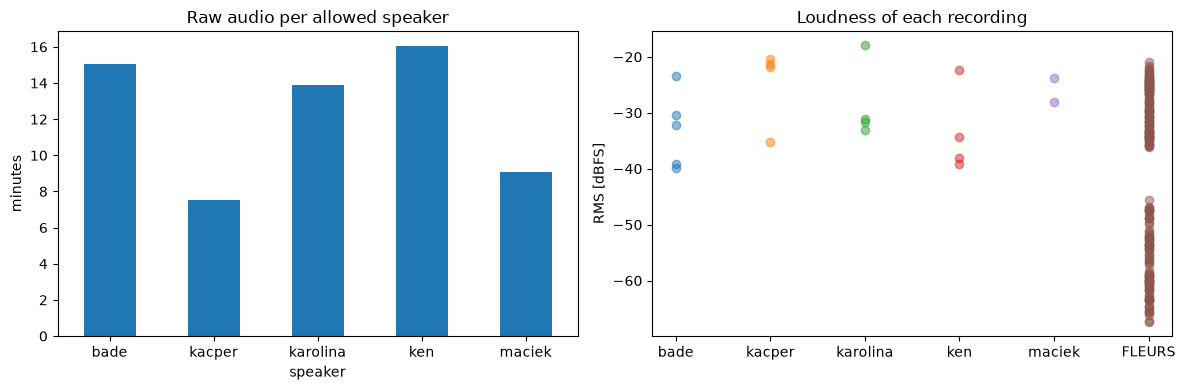

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

(allowed_raw.groupby("speaker")["duration"].sum() / 60).plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Raw audio per allowed speaker")
axes[0].set_ylabel("minutes")

speakers = sorted(allowed_raw["speaker"].unique()) + ["FLEURS"]
for i, name in enumerate(speakers):
    values = recordings[recordings["speaker"] == name]["rms_db"]
    axes[1].scatter(np.full(len(values), i), values, alpha=0.5)
axes[1].set_xticks(range(len(speakers)), speakers)
axes[1].set_title("Loudness of each recording")
axes[1].set_ylabel("RMS [dBFS]")

plt.tight_layout()
plt.show()

## 2. Chunks




In [5]:
def load_manifest(name):
    df = pd.read_csv(data / name / "manifest.csv")
    df["path"] = [data / name / f for f in df["chunk_file"]]
    df["class"] = name.replace("_", " ")
    return df


chunks = pd.concat([load_manifest("allowed"), load_manifest("not_allowed")], ignore_index=True)
chunks["group"] = [p.relative_to(data).parts[1] for p in chunks["path"]]

print("missing files:", sum(not p.is_file() for p in chunks["path"]))
chunks.groupby(["class", "label"]).size()

missing files: 0


class        label
allowed      1         1774
not allowed  0        21068
dtype: int64

In [6]:
chunks.groupby("class").agg(
    chunks=("chunk_file", "count"),
    recordings=("source_file", "nunique"),
    total_min=("duration_seconds", lambda s: s.sum() / 60),
    mean_duration=("duration_seconds", "mean"),
    mean_speech_ratio=("speech_ratio", "mean"),
).round(2)

,chunks,recordings,total_min,mean_duration,mean_speech_ratio
class,,,,,
allowed,1774,19,59.99,2.03,0.95
not allowed,21068,3224,700.79,2.00,0.89


In [7]:
per_group = chunks.groupby(["class", "group"]).agg(
    chunks=("chunk_file", "count"),
    recordings=("source_file", "nunique"),
    total_min=("duration_seconds", lambda s: s.sum() / 60),
).reset_index()

per_group["chunks_per_recording"] = per_group["chunks"] / per_group["recordings"]
per_group.round(1)

,class,group,chunks,recordings,total_min,chunks_per_recording
0,allowed,bade,433,5,14.8,86.6
1,allowed,kacper,216,4,7.3,54.0
2,allowed,karolina,398,4,13.5,99.5
3,allowed,ken,463,4,15.8,115.8
4,allowed,maciek,264,2,8.7,132.0
5,not allowed,audios_mult,10365,1000,344.6,10.4
6,not allowed,audios_pl,1645,997,54.9,1.6
7,not allowed,audios_tr,434,55,14.6,7.9
8,not allowed,eng,8624,1172,286.6,7.4


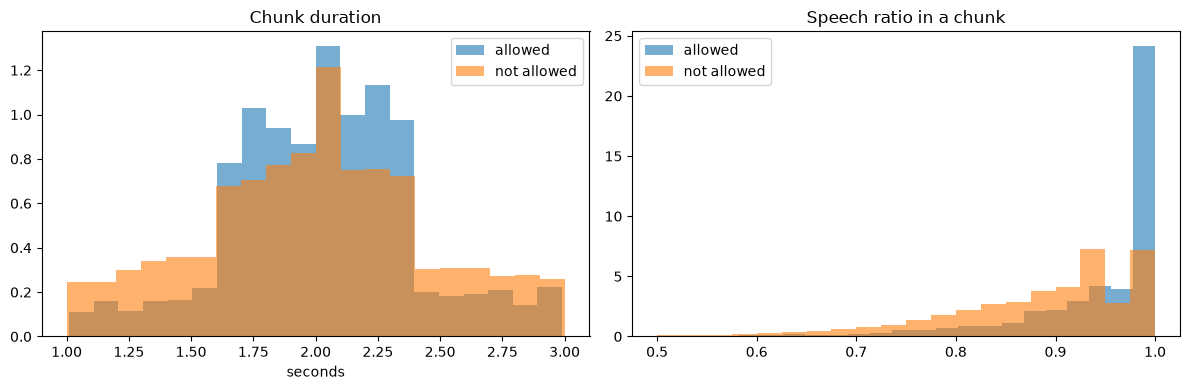

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, group in chunks.groupby("class"):
    axes[0].hist(group["duration_seconds"], bins=20, alpha=0.6, density=True, label=name)
    axes[1].hist(group["speech_ratio"], bins=20, alpha=0.6, density=True, label=name)
axes[0].set_title("Chunk duration")
axes[0].set_xlabel("seconds")
axes[0].legend()
axes[1].set_title("Speech ratio in a chunk")
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
skipped = pd.concat([
    pd.read_csv(data / "allowed" / "skipped.csv").assign(**{"class": "allowed"}),
    pd.read_csv(data / "not_allowed" / "skipped.csv").assign(**{"class": "not allowed"}),
])
pd.crosstab(skipped["class"], skipped["reason"])

reason,low_speech_ratio,no_speech_detected,short_speech_region
class,,,
allowed,6,0,25
not allowed,247,84,3190


## 3. Data quality

In [10]:
sources = chunks.drop_duplicates("source_file")
pd.crosstab([sources["class"], sources["group"]], [sources["sample_rate"], sources["channels"]])

sample_rate             16000 32000 44100    48000   
channels                    1     1     1  2     1  2
class       group                                    
allowed     bade            0     0     0  0     2  3
            kacper          0     0     0  0     1  3
            karolina        3     0     1  0     0  0
            ken             1     0     0  0     1  2
            maciek          0     0     0  2     0  0
not allowed audios_mult     0  1000     0  0     0  0
            audios_pl       0     0     0  0   997  0
            audios_tr       0    55     0  0     0  0
            eng             0  1172     0  0     0  0

In [11]:
def audio_hash(path):
    audio, _ = sf.read(path, dtype="float32")
    return hashlib.md5(audio.tobytes()).hexdigest()


chunk_hashes = [audio_hash(p) for p in chunks["path"]]
raw_hashes = [audio_hash(p) for p in raw_dir.rglob("*.wav")]

print("chunks:", len(chunk_hashes), "unique:", len(set(chunk_hashes)))
print("raw recordings:", len(raw_hashes), "unique:", len(set(raw_hashes)))

chunks: 22842 unique: 22842
raw recordings: 199 unique: 199
